==========================================================SEASOON_14==========================================================

1.Download a small dataset of IPL cricket matches (CSV or Excel), load it into a pandas DataFrame, and perform univariate analysis by printing the summary statistics (mean, median, min, max, std) for the 'total_runs' column

In [7]:

df = pd.read_csv("ipl_matches.csv") 

data = {
    'match_id': [1,2,3,4,5,6,7,8,9,10],
    'season': [2023,2023,2023,2023,2023,2024,2024,2024,2024,2024],
    'team1': ['CSK','MI','RCB','KKR','GT','CSK','MI','LSG','RR','PBKS'],
    'team2': ['GT','RCB','KKR','LSG','MI','RCB','CSK','GT','KKR','DC'],
    'total_runs': [205, 178, 212, 165, 189, 198, 225, 142, 176, 201],
}
df = pd.DataFrame(data)

print(df.head())

col = df['total_runs']

print("\n--- Univariate Analysis for 'total_runs' ---")
print(f"Mean: {col.mean()}")
print(f"Median: {col.median()}")
print(f"Min: {col.min()}")
print(f"Max: {col.max()}")
print(f"Std Dev: {col.std()}")

# Detailed summary
print(col.describe())

   match_id  season team1 team2  total_runs
0         1    2023   CSK    GT         205
1         2    2023    MI   RCB         178
2         3    2023   RCB   KKR         212
3         4    2023   KKR   LSG         165
4         5    2023    GT    MI         189

--- Univariate Analysis for 'total_runs' ---
Mean: 189.1
Median: 193.5
Min: 142
Max: 225
Std Dev: 24.45153937439886
count     10.000000
mean     189.100000
std       24.451539
min      142.000000
25%      176.500000
50%      193.500000
75%      204.000000
max      225.000000
Name: total_runs, dtype: float64


2.Using a dataset of Flipkart product reviews (at least columns: 'rating', 'category'), create a bar plot showing the count of reviews for each rating (1-5 stars) using matplotlib or seaborn.

rating
2    1
3    1
4    4
5    4
Name: count, dtype: int64


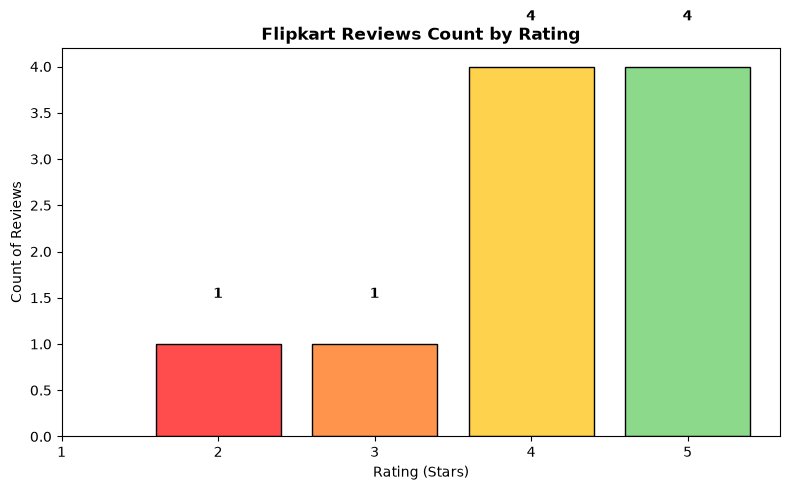

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("flipkart_reviews.csv")

rating_counts = df['rating'].value_counts().sort_index()
print(rating_counts)

plt.figure(figsize=(8,5))
colors = ['#ff4d4d','#ff944d','#ffd24d','#8cd98c','#4da6ff']

bars = plt.bar(rating_counts.index, rating_counts.values, color=colors, edgecolor='black')
plt.title('Flipkart Reviews Count by Rating', fontweight='bold')
plt.xlabel('Rating (Stars)')
plt.ylabel('Count of Reviews')
plt.xticks([1,2,3,4,5])

for bar in bars:
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height()+0.5, 
             int(bar.get_height()), ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig("flipkart_rating.png")
plt.show()



3.Take a dataset of Zomato restaurant listings (with 'average_cost_for_two' and 'user_rating' columns) and create a scatterplot to visualize the relationship between cost and user rating.<br><br><em><strong>Hint:</strong> Use seaborn's scatterplot() function and label the axes clearly.</em>

    restaurant_name  average_cost_for_two  user_rating
0    Domino's Pizza                   400          3.8
1  Paradise Biryani                   800          4.3
2           Bukhara                  3500          4.7
3           Gajalee                  1200          4.1
4     Meghana Foods                   600          4.4


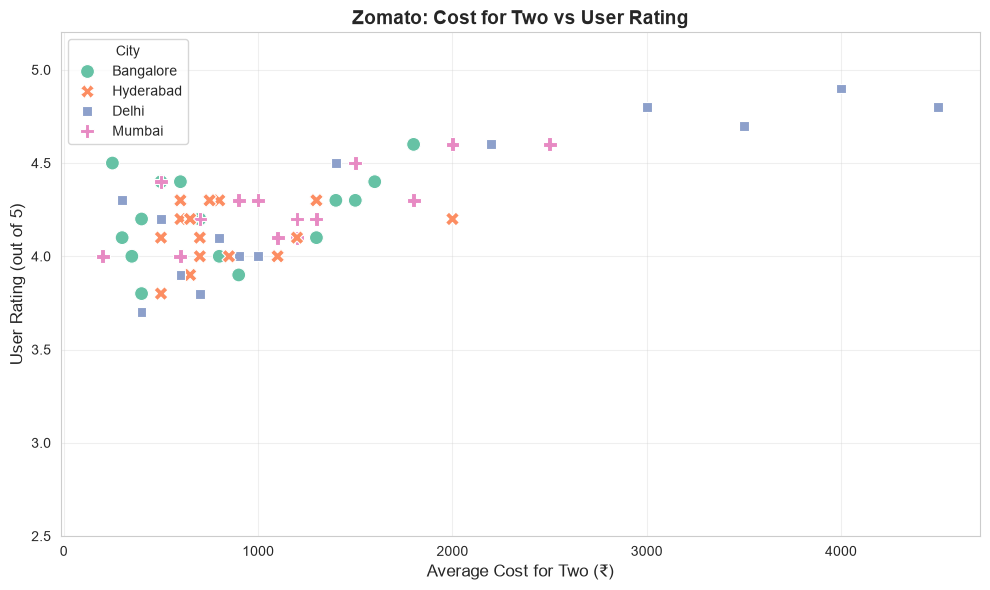

Correlation: 0.7288268779548801


In [21]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the text file
df = pd.read_csv("zomato.txt")
# If you saved as .csv : df = pd.read_csv("zomato.csv")

print(df[['restaurant_name','average_cost_for_two','user_rating']].head())

# Create Scatterplot
plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='average_cost_for_two', y='user_rating', 
                hue='city', style='city', s=100, palette='Set2')

# Label axes clearly [as per question]
plt.title('Zomato: Cost for Two vs User Rating', fontsize=14, fontweight='bold')
plt.xlabel('Average Cost for Two (₹)', fontsize=12)
plt.ylabel('User Rating (out of 5)', fontsize=12)
plt.ylim(2.5, 5.2)
plt.grid(True, alpha=0.3)
plt.legend(title='City')
plt.tight_layout()
plt.savefig("zomato_scatter.png")
plt.show()

# Extra: Correlation
print("Correlation:", df['average_cost_for_two'].corr(df['user_rating']))

4.For a BookMyShow movie dataset (with 'genre' and 'box_office_collection' columns), use groupby analysis to find the average box office collection for each genre and display the results as a sorted table

In [14]:
import pandas as pd

# 1. Load BookMyShow dataset
df = pd.read_csv("bookmyshow_movies.csv")
# Columns required: genre, box_office_collection

# Check sample
print(df.head())

# 2. Groupby analysis - Average box office per genre
genre_avg = df.groupby('genre')['box_office_collection'].mean().reset_index()
genre_avg = genre_avg.rename(columns={'box_office_collection':'avg_box_office_cr'})

# Round to 2 decimals
genre_avg['avg_box_office_cr'] = genre_avg['avg_box_office_cr'].round(2)

# 3. Sort descending by average collection
genre_avg_sorted = genre_avg.sort_values(by='avg_box_office_cr', ascending=False)

print(genre_avg_sorted)

# Extra - detailed stats
genre_stats = df.groupby('genre').agg(
    avg_collection=('box_office_collection','mean'),
    total_movies=('genre','count'),
    max_collection=('box_office_collection','max')
).round(2).sort_values('avg_collection', ascending=False)

print(genre_stats)

   movie_id movie_name   genre  box_office_collection
0         1    Pathaan  Action                    543
1         2      Jawan  Action                    640
2         3    Gadar 2  Action                    525
3         4     Animal  Action                    554
4         5        WAR  Action                    318
       genre  avg_box_office_cr
0     Action             437.67
6     Sci-Fi             413.25
3      Drama             253.00
4     Horror             197.50
2     Comedy             194.86
7   Thriller             141.25
5    Romance             123.50
1  Animation             101.50
           avg_collection  total_movies  max_collection
genre                                                  
Action             437.67             9             640
Sci-Fi             413.25             4             646
Drama              253.00             4             387
Horror             197.50             6             627
Comedy             194.86             7             

5.Use the seaborn 'pairplot' function on a Spotify songs dataset (with at least 'danceability', 'energy', 'valence', and 'popularity' columns) to visualize pairwise relationships between these features. Briefly describe one interesting pattern you observe

   danceability  energy  valence  popularity
0          0.51    0.73     0.33          90
1          0.52    0.62     0.66          91
2          0.70    0.83     0.91          89
3          0.59    0.62     0.48          88
4          0.56    0.72     0.56          90


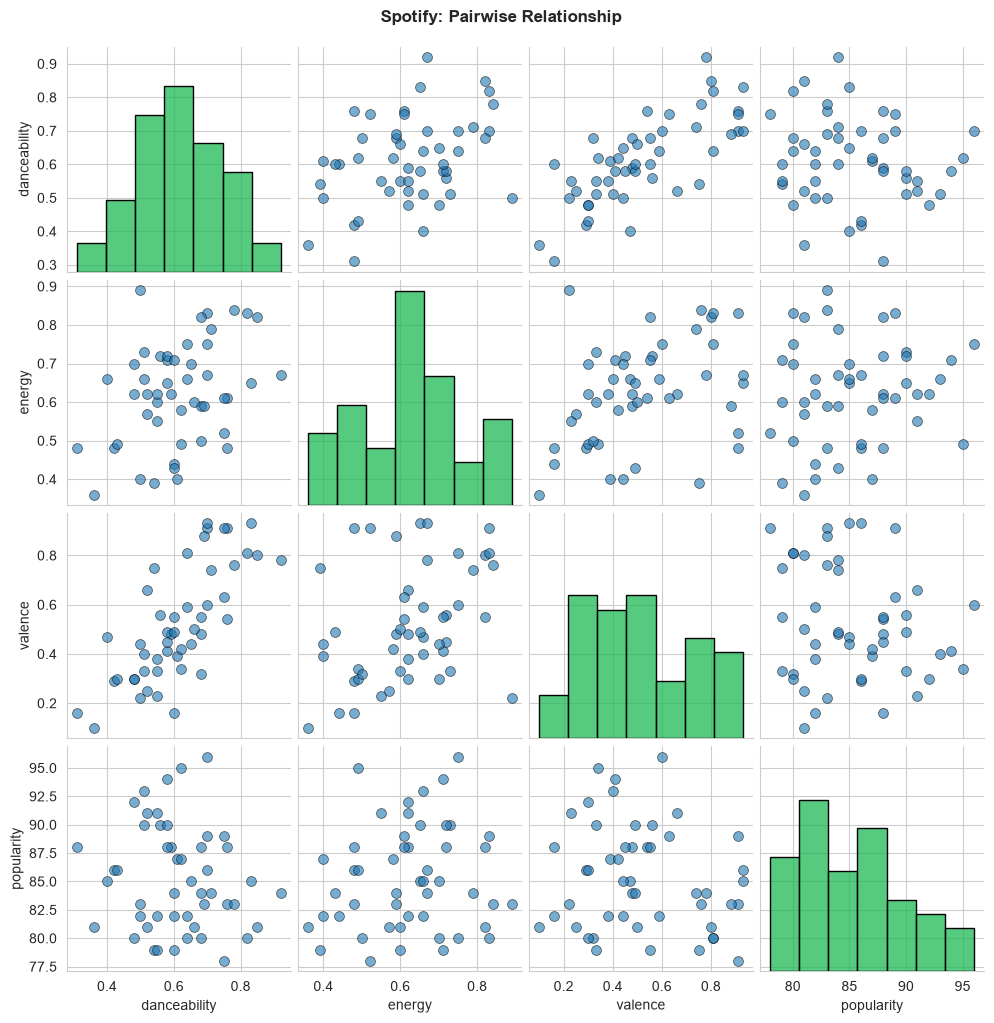

              danceability    energy   valence  popularity
danceability      1.000000  0.374334  0.745236   -0.136517
energy            0.374334  1.000000  0.352439    0.123152
valence           0.745236  0.352439  1.000000   -0.165211
popularity       -0.136517  0.123152 -0.165211    1.000000


In [19]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("spotify_songs.csv")


print(df[['danceability','energy','valence','popularity']].head())

# 2. Pairplot - Visualize pairwise relationships
sns.set_style("whitegrid")
g = sns.pairplot(df[['danceability','energy','valence','popularity']], 
                 diag_kind='hist', 
                 plot_kws={'alpha':0.6, 's':50, 'edgecolor':'k'},
                 diag_kws={'color':'#1DB954', 'edgecolor':'black'})

g.fig.suptitle("Spotify: Pairwise Relationship", y=1.02, fontweight='bold')
plt.savefig("spotify_pairplot.png")
plt.show()

# 3. Correlation for analysis
print(df[['danceability','energy','valence','popularity']].corr())